<a href="https://colab.research.google.com/github/MarceloCoccaro12/Weather-Type-Classification/blob/main/Weather_Type_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importando Dataset do Kaggle

In [ ]:
!kaggle datasets download -d nikhil7280/weather-type-classification --unzip -p /content/dados

Dataset URL: https://www.kaggle.com/datasets/nikhil7280/weather-type-classification
License(s): other
100% 186k/186k [00:00<00:00, 80.1MB/s]



# Importando Bibliotecas

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
wcd = pd.read_csv('/content/dados/weather_classification_data.csv')

In [ ]:
wcd.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy


# Quantidades de rótulos

In [ ]:
wcd['Weather Type'].unique()

array(['Rainy', 'Cloudy', 'Sunny', 'Snowy'], dtype=object)

In [ ]:
wcd.isnull().sum()

,0
Temperature,0
Humidity,0
Wind Speed,0
Precipitation (%),0
Cloud Cover,0
Atmospheric Pressure,0
UV Index,0
Season,0
Visibility (km),0
Location,0


In [ ]:
wcd.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
13195,False
13196,False
13197,False
13198,False


In [ ]:
wcd.describe()

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


In [ ]:
wcd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB


In [ ]:
X = wcd.drop('Weather Type', axis=1)
y = wcd['Weather Type']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
numerical_features = ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)', 'Atmospheric Pressure', 'UV Index', 'Visibility (km)']
categorical_features = ['Cloud Cover', 'Season', 'Location']

In [ ]:
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

In [ ]:
preprocessor = ColumnTransformer(
    transformers= [
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
)

In [ ]:
model_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('classifier', SVC(kernel='rbf'))])

In [ ]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Temperature', 'Humidity',
                                                   'Wind Speed',
                                                   'Precipitation (%)',
                                                   'Atmospheric Pressure',
                                                   'UV Index',
                                                   'Visibility (km)']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Cloud Cover', 'Season',
                                                   'Location'])])),
                ('classifier', SVC())])

In [ ]:
y_pred = model_pipeline.predict(X_test)

In [ ]:
acuracia = accuracy_score(y_test, y_pred)
print(f'Acurácia: {acuracia * 100:.2f}%')

Acurácia: 90.72%


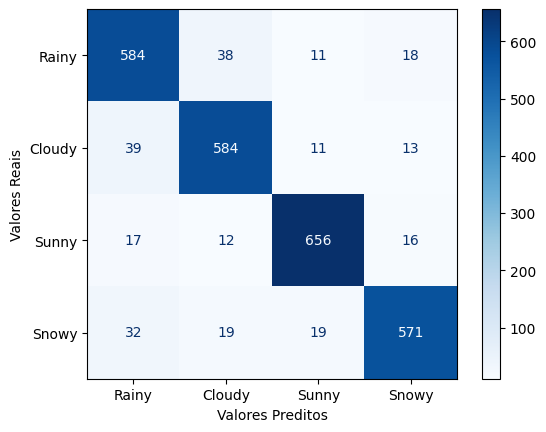

In [ ]:
classes = ['Rainy', 'Cloudy', 'Sunny', 'Snowy']
cm = confusion_matrix(y_test, y_pred)
matrix = ConfusionMatrixDisplay(cm, display_labels= classes)
matrix.plot(cmap=plt.cm.Blues)
plt.xlabel('Valores Preditos')
plt.ylabel('Valores Reais')
plt.show()

In [ ]:
param_grid = {
    'classifier__C' : [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.1, 1],
    'classifier__kernel' : ['linear', 'rbf', 'poly', 'sigmoid']
}

grid_search = GridSearchCV(
    model_pipeline,
    param_grid,
    cv = 5,
    scoring='accuracy',
    verbose = 2,
    n_jobs = -1
)

grid_search.fit(X_train, y_train)

# Obter melhores parâmetros e melhor pontuação de validação cruzada
best_param = grid_search.best_params_
best_score = grid_search.best_score_

print(f'Melhores parâmetros encontrados: {best_param}')
print(f'Melhor Acurácia Média (VC) encontrada: {best_score * 100:.2f}%')

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Melhores parâmetros encontrados: {'classifier__C': 10, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
Melhor Acurácia Média (VC) encontrada: 91.07%


In [ ]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
acuracia_test = accuracy_score(y_test, y_pred_tuned)
print(f'Acurácia do conjunto de teste: {acuracia_test * 100:.2f}%')

Acurácia do conjunto de teste: 90.76%


# Matriz de Confusão do Conjunto de Testes

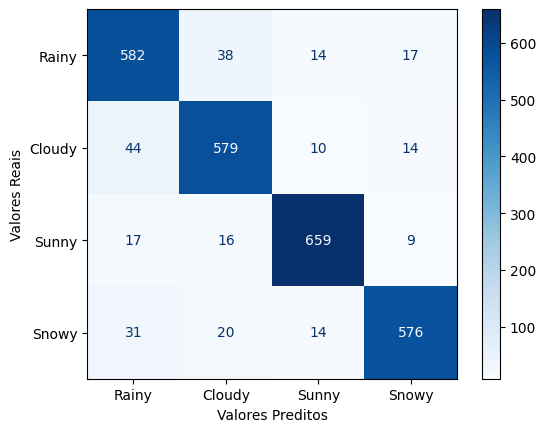

In [ ]:
classes = ['Rainy', 'Cloudy', 'Sunny', 'Snowy']
cm = confusion_matrix(y_test, y_pred_tuned)
matrix = ConfusionMatrixDisplay(cm, display_labels=classes)
matrix.plot(cmap=plt.cm.Blues)
plt.xlabel('Valores Preditos')
plt.ylabel('Valores Reais')
plt.show()